# Задание 4.1
## Выборка без возвращения и с возвращением (классическое определение вероятности)

### Условие:
Корзина содержит 23 шара: 8 белых, 6 синих и 9 красных. На каждом шаге из корзины «наудачу» извлекается шар. Из корзины наудачу (без возвращения) извлечены 6 шаров. Найдите вероятности событий и покажите их статистическую устойчивость: а) $A=\{$все шары красные$\}$; б) $B=\{$3 синих, 2 белых и 1 красный$\}$; в) $D=\{$ровно 4 белых$\}$. г) Разобрать случай извлечения шаров **с возвращением**: найти $\mathbb P(A)$, если «статистическая вероятность» $\hat p(A)\approx0{,}00358549$.

### Теория:
**Классическое определение:** если опыт имеет $n$ равновозможных элементарных исходов и событию $A$ благоприятствуют $m$ из них, то $\mathbb P(A)=m/n$.
**Бесповторная выборка** объёма 6 «наудачу» из 23 шаров: все $C_{23}^6$ **неупорядоченных** наборов (сочетаний) равновозможны. **Гипергеометрическая формула:** вероятность взять $k_1$ шаров 1-го цвета, $k_2$ — 2-го, $k_3$ — 3-го ($k_1+k_2+k_3=6$):
$$\mathbb P=\frac{C_{8}^{k_1}C_{6}^{k_2}C_{9}^{k_3}}{C_{23}^{6}} .$$
**Статистическая вероятность (относительная частота)** $\hat p_N(A)=\dfrac{N(A)}{N}$, где $N(A)$ — число опытов, в которых $A$ произошло. По закону больших чисел $\hat p_N(A)\to\mathbb P(A)$ при $N\to\infty$ (**статистическая устойчивость**).

### Решение:
Число всех исходов: $C_{23}^6=\dfrac{23\cdot22\cdot21\cdot20\cdot19\cdot18}{6!}=100\,947$.

**а)** Все 6 шаров красные: выбираем 6 из 9 красных: $C_9^6=84$. 
$$\mathbb P(A)=\frac{84}{100947}=\frac{4}{4807}\approx0{,}000832120 .$$
**б)** 3 синих из 6, 2 белых из 8, 1 красный из 9: $C_6^3C_8^2C_9^1=20\cdot28\cdot9=5040$. 
$$\mathbb P(B)=\frac{5040}{100947}=\frac{240}{4807}\approx0{,}049927 .$$
**в)** Ровно 4 белых из 8 и остальные 2 шара — из 15 небелых (6 синих + 9 красных): $C_8^4C_{15}^2=70\cdot105=7350$. 
$$\mathbb P(D)=\frac{7350}{100947}=\frac{350}{4807}\approx0{,}072811 .$$
**г) С возвращением.** Каждый шар возвращается, поэтому 6 извлечений независимы; равновозможны **упорядоченные** исходы: $23^6$ штук. Событию $A$ (все красные) благоприятствуют $9^6$ исходов:
$$\mathbb P(A)=\Bigl(\frac{9}{23}\Bigr)^6=\frac{531441}{148035889}\approx0{,}0035899 .$$
Если «статистическая вероятность» получена по $N=10^6$ опытам, её стандартная ошибка $\sqrt{P(1-P)/N}\approx6\cdot10^{-5}$, поэтому значение $\hat p(A)\approx0{,}00358549$ отличается от точного $0{,}0035899$ всего на $\approx0{,}07\sigma$ — оно согласуется с этой вероятностью.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Точные вероятности (`fractions.Fraction` — точные дроби)

In [2]:
total = comb(23, 6)                                          # число всех выборок объёма 6 из 23
P_A = Fraction(comb(9, 6), total)                            # все красные
P_B = Fraction(comb(6, 3)*comb(8, 2)*comb(9, 1), total)      # 3 синих, 2 белых, 1 красный
P_D = Fraction(comb(8, 4)*comb(15, 2), total)                # ровно 4 белых
P_A_repl = Fraction(9, 23)**6                                # с возвращением: (9/23)^6
print('C(23,6) =', total)
for name, P in [('A', P_A), ('B', P_B), ('D', P_D), ('A (с возвращением)', P_A_repl)]:
    print(f'P({name}) = {P} ≈ {float(P):.12f}')

C(23,6) = 100947
P(A) = 4/4807 ≈ 0.000832119825
P(B) = 240/4807 ≈ 0.049927189515
P(D) = 350/4807 ≈ 0.072810484710
P(A (с возвращением)) = 531441/148035889 ≈ 0.003589947030


### Моделирование
В каждом опыте шары нумеруем (0 — белый, 1 — синий, 2 — красный). **Без возвращения:** строим случайную перестановку 23 шаров (сортировка случайных чисел) и берём первые 6. **С возвращением:** 6 раз независимо выбираем номер шара из 23. Всего $N=10^6$ опытов (порциями, чтобы не занимать много памяти).

In [3]:
colors = np.array([0]*8 + [1]*6 + [2]*9)                      # цвет каждого из 23 шаров
N = 1_000_000

def draw_without_replacement(N, chunk=100_000):
    # Возвращает массив (N × 3): сколько белых, синих, красных среди 6 извлечённых без возвращения
    out = np.zeros((N, 3), dtype=np.int8)
    for s in range(0, N, chunk):
        m = min(chunk, N - s)
        idx = np.argsort(rng.random((m, 23)), axis=1)[:, :6]    # случайная перестановка шаров, первые 6 = выборка без возвращения
        c = colors[idx]                                          # цвета извлечённых шаров (m × 6)
        for k in range(3): out[s:s + m, k] = (c == k).sum(axis=1)
    return out

cnt = draw_without_replacement(N)
hit_A = cnt[:, 2] == 6                                         # все красные
hit_B = (cnt[:, 0] == 2) & (cnt[:, 1] == 3) & (cnt[:, 2] == 1) # 2 белых, 3 синих, 1 красный
hit_D = cnt[:, 0] == 4                                         # ровно 4 белых

# с возвращением: 6 независимых выборов номера шара из 23
hit_A2 = np.zeros(N, dtype=bool)
for s in range(0, N, 200_000):
    draws = rng.integers(0, 23, size=(min(200_000, N - s), 6))
    hit_A2[s:s + len(draws)] = (colors[draws] == 2).all(axis=1)

for name, h, P in [('A', hit_A, P_A), ('B', hit_B, P_B), ('D', hit_D, P_D), ('A, с возвращением', hit_A2, P_A_repl)]:
    print(f'--- событие {name}: точное P = {float(P):.7f}'); table(h, float(P))

--- событие A: точное P = 0.0008321
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.0000000   8.32e-04   8.65e-03
     1000   0.0010000   1.68e-04   2.74e-03
    10000   0.0007000   1.32e-04   8.65e-04
   100000   0.0007900   4.21e-05   2.74e-04
  1000000   0.0008120   2.01e-05   8.65e-05
--- событие B: точное P = 0.0499272
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.0600000   1.01e-02   6.53e-02
     1000   0.0540000   4.07e-03   2.07e-02
    10000   0.0521000   2.17e-03   6.53e-03
   100000   0.0500600   1.33e-04   2.07e-03
  1000000   0.0500430   1.16e-04   6.53e-04
--- событие D: точное P = 0.0728105
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.1000000   2.72e-02   7.79e-02
     1000   0.0790000   6.19e-03   2.46e-02
    10000   0.0737000   8.90e-04   7.79e-03
   100000   0.0736700   8.60e-04   2.46e-03
  1000000   0.0729690   1.59e-04   7.79e-04
--- событие A, с возвращением: точное P = 0.0035899
       N        p̂(N)        |p̂ − P

### Графики: статистическая устойчивость относительной частоты $\hat p_N(A)$

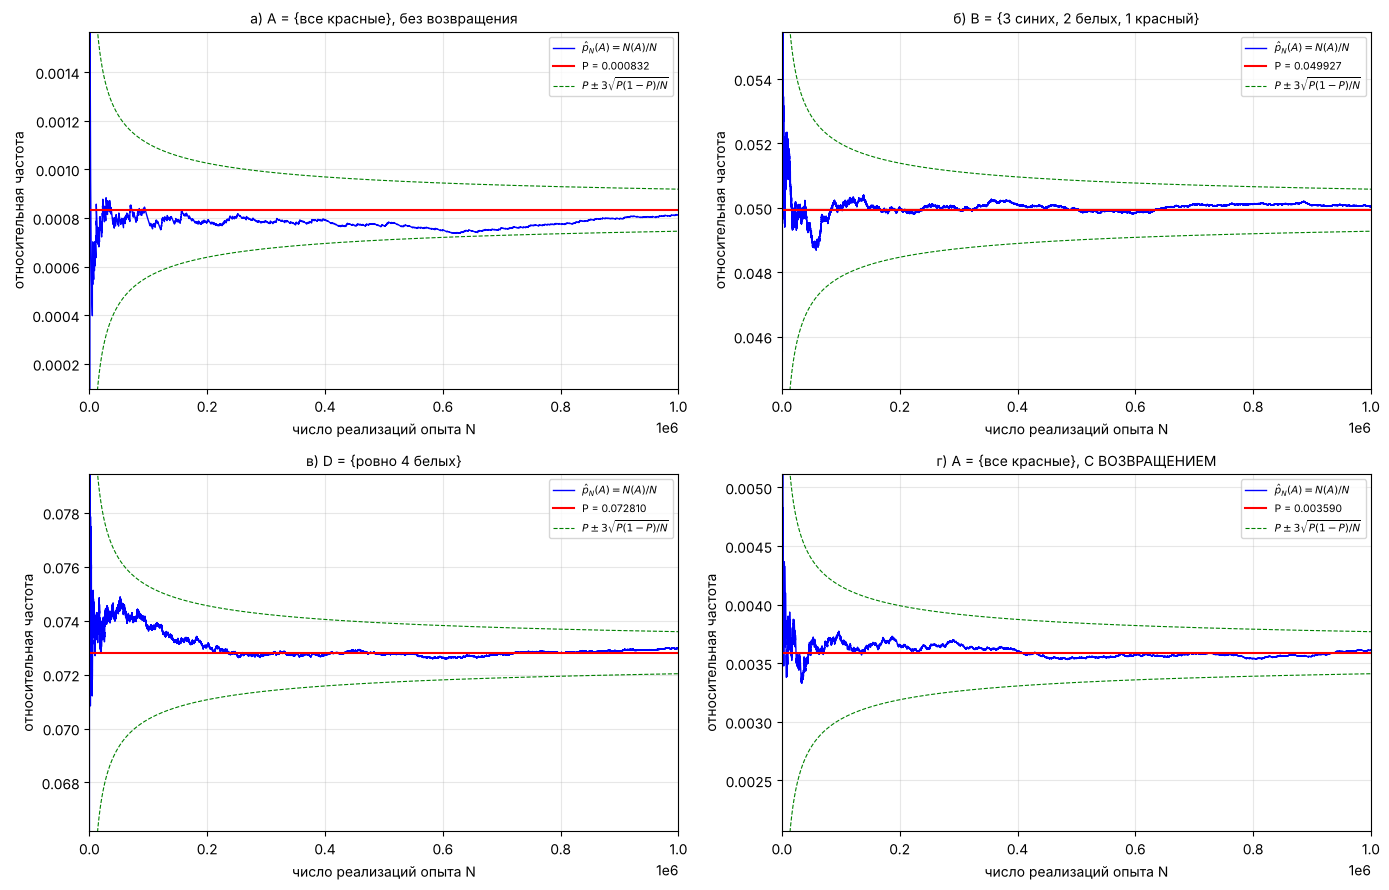

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
plot_frequency(axs[0, 0], hit_A, float(P_A), 'а) A = {все красные}, без возвращения')
plot_frequency(axs[0, 1], hit_B, float(P_B), 'б) B = {3 синих, 2 белых, 1 красный}')
plot_frequency(axs[1, 0], hit_D, float(P_D), 'в) D = {ровно 4 белых}')
plot_frequency(axs[1, 1], hit_A2, float(P_A_repl), 'г) A = {все красные}, С ВОЗВРАЩЕНИЕМ')
plt.tight_layout(); plt.savefig('task_4_1.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
а) $\mathbb P(A)=\dfrac{4}{4807}\approx0{,}000832120$; б) $\mathbb P(B)=\dfrac{240}{4807}\approx0{,}049927$; в) $\mathbb P(D)=\dfrac{350}{4807}\approx0{,}072811$; 
г) с возвращением $\mathbb P(A)=\Bigl(\dfrac{9}{23}\Bigr)^6\approx0{,}0035899$ (статистическая оценка $0{,}00358549$ ей соответствует). На графиках относительная частота колеблется всё меньше и приближается к точному значению (красная линия), оставаясь внутри «коридора» $\pm3\sigma$.